In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import lqproblem
import optimiser_lqproblem
from math import factorial
import pickle

C:\Users\User\anaconda3\Lib\site-packages\torch\__init__.py:1275: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\tensor\python_tensor.cpp:436.)
  _C._set_default_tensor_type(t)


In [2]:
b0 = 1
b1 = 5e-1
b2 = 1e-1
sigma0 = 5e-1
sigma2 = 1e-1

params = {'b0': b0, 'b1': b1, 'b2': b2,
          'sigma0': sigma0, 'sigma2': sigma2, 'X0': 10, 
          'A': 0, 'B': 1, 'C': 0, 'D':0, 'E':1, 'G': 0,
          'T': 0.10, 'Nt': 1_000}

env = lqproblem.environment(**params)
env_hjb = lqproblem.environment(**params)
env_hjb_sig = lqproblem.environment(**params)

In [3]:
max_order_x = 8
max_order_fn = 6
poly_deg = 10
max_order_F = 4

In [4]:
F_HJB = lqproblem.strategy_hjb_sig_functional(env, poly_deg, max_order_F)

In [5]:
np.random.seed(456)
dim = 2
order = max_order_F

# with open('W_sig_1.pkl', 'rb') as f:
#     W_sig_expected = pickle.load(f)
#     f.close()

W_sig_expected = lqproblem.fawcett(env, max_order_x)
#W_sig = W_sig_expected.flatten()

# with open('F_optimised_problem2.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()
    
#env = lqproblem.environment(**params)
optimiser_1 = optimiser_lqproblem.Optimiser(env, W_sig_expected, order = order, max_order_fn = max_order_fn)
#F = ta.sig_to_tensor(F, env.dim, order)
#optimiser_1.F = F

In [6]:
with open('W_sig_1.pkl', 'rb') as f:
    W_sig_expected_empirical = pickle.load(f)
    f.close()

In [7]:
W_sig_expected

Tensor([1.0, [0.1, 0.0], [[0.005000000000000001, 0.0], [0.0, 0.05]], [[[0.0001666666666666667, 0.0], [0.0, 0.0025000000000000005]], [[0.0, 0.0], [0.0025000000000000005, 0.0]]], [[[[4.166666666666668e-06, 0.0], [0.0, 8.333333333333334e-05]], [[0.0, 0.0], [8.333333333333334e-05, 0.0]]], [[[0.0, 0.0], [0.0, 0.0]], [[8.333333333333334e-05, 0.0], [0.0, 0.0012500000000000002]]]], [[[[[8.333333333333336e-08, 0.0], [0.0, 2.083333333333334e-06]], [[0.0, 0.0], [2.083333333333334e-06, 0.0]]], [[[0.0, 0.0], [0.0, 0.0]], [[2.083333333333334e-06, 0.0], [0.0, 4.166666666666667e-05]]]], [[[[0.0, 0.0], [0.0, 0.0]], [[0.0, 0.0], [0.0, 0.0]]], [[[2.083333333333334e-06, 0.0], [0.0, 4.166666666666667e-05]], [[0.0, 0.0], [4.166666666666667e-05, 0.0]]]]], [[[[[[1.3888888888888894e-09, 0.0], [0.0, 4.166666666666668e-08]], [[0.0, 0.0], [4.166666666666668e-08, 0.0]]], [[[0.0, 0.0], [0.0, 0.0]], [[4.166666666666668e-08, 0.0], [0.0, 1.041666666666667e-06]]]], [[[[0.0, 0.0], [0.0, 0.0]], [[0.0, 0.0], [0.0, 0.0]]],

In [8]:
W_sig_expected_empirical.truncate(max_order_x)

Tensor([1.0, [0.10000000000000002, 0.0005403420705326324], [[0.0049999999999999776, -3.4747464107733884e-05], [8.878167116099732e-05, 0.049994834951523175]], [[[0.0001666666666666665, -3.1323807145444995e-06], [2.790015018315637e-06, 0.002504765537018156]], [[3.0440760488920427e-06, 7.946128566998151e-06], [0.0024867718295671624, -5.19398713656144e-07]]], [[[[4.166666666666648e-06, -1.209890596021725e-07], [4.972910735206816e-08, 8.351364516424937e-05]], [[8.977164356371352e-08, 3.5853502145855343e-07], [8.309072835185775e-05, 3.690634172024708e-07]]], [[[7.154532044183017e-08, 2.634036741229082e-07], [-9.072951300455443e-08, 3.487185491327115e-07]], [[8.283859205893151e-05, -2.3543674177182934e-06], [1.5846455800174974e-06, 0.0012468553139285416]]]], [[[[[8.333333333333331e-08, -3.128010619573796e-09], [4.131365180778849e-10, 2.0878252656917165e-06]], [[1.866750590486595e-09, 8.681253366080547e-09], [2.0792074659837168e-06, -5.8151444096097335e-09]]], [[[1.7478877251327174e-09, 7.6012

In [9]:
np.random.seed(456)
n_epochs = 50
lr = 5

optimiser_1.train_sgd(n_epochs, lr = lr, max_order_x = max_order_x, max_order_fn = max_order_fn, truncate_fn = True, method='SGD')

F = optimiser_1.F

strag_sig = lqproblem.sig_strag_dot(F, order = order)

[101.86901171]: 100%|██████████| 50/50 [06:49<00:00,  8.19s/it]


In [10]:
F

Tensor([-4.998938992485819, [-0.1763410138526531, -0.5603283968461135], [[-0.3390380444346047, -1.6063437555302298], [-1.3887531893572307, -0.09971597532131951]], [[[0.8460474515010215, 0.6352758844594862], [0.7446447164724809, 2.7550232328975963]], [[0.0045480876283695935, 0.727392403197918], [-0.3492110708661104, -0.6403981697171325]]], [[[[0.4616022850989261, 0.3232126626981769], [0.2610975172812635, -0.6679802871081558]], [[-0.024773251638486364, 0.5403743699220043], [-0.5814229213569713, 0.8673700561493825]]], [[[-0.7742069217050942, 0.7915950608450398], [-0.11076904639803896, -0.23369221488086828]], [[-0.4247370775383887, 0.8483660553194924], [0.04063284001294691, 1.2707575577258705]]]]])

In [11]:
F_HJB

Tensor([-5.038491780529354, [0.6412475175229668, -0.7477811533459178], [[-0.10605300121560635, 0.0040051220163394505], [0.08973373840204817, -0.07477811533459179]], [[[13.582939668557831, -0.01797450916023874], [-0.0004806148657101198, 0.0004005122016339439]], [[-0.01076804883205685, 0.008973373840204815], [0.008973373840204815, -0.00747781153345918]]], [[[[-2984.900366084123, -0.0012554609259900938], [0.0021570066230240446, -0.001797450916023874]], [[5.773933331921577e-05, -4.8061486571012065e-05], [-4.80614865710125e-05, 4.0051220163394256e-05]]], [[[0.0012922314349394178, -0.0010768048832056848], [-0.001076804883205685, 0.0008973373840204815]], [[-0.0010768048832056852, 0.0008973373840204818], [0.0008973373840204822, -0.000747781153345918]]]]])

In [12]:
F = optimiser_1.F

strag_sig = lqproblem.sig_strag_dot(F, order = order)

In [13]:
# # F = optimiser_1.F

# # strag_sig = lqproblem.sig_strag_dot(F, order = order)

# with open('F_optimised_problem2.pkl', 'wb') as f:
#     pickle.dump(F.flatten(), f)
#     f.close()

In [14]:
np.random.seed(123)

nsims = 10

env.simulate(nsims, strag_sig, max_order_x)

C:\Users\User\Documents\GitHub\optimal-control-with-signatures\notebooks\../src\lqproblem.py:136: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  strag[nsim] = F.dot(W_sig)


In [15]:
np.random.seed(123)

env_hjb.simulate(nsims, lqproblem.strategy_hjb_feedback, max_order_x)

In [16]:
np.random.seed(123)

strag_hjb_sig = lqproblem.sig_strag_dot(F_HJB, order = order)

env_hjb_sig.simulate(nsims, strag_hjb_sig, max_order_x)

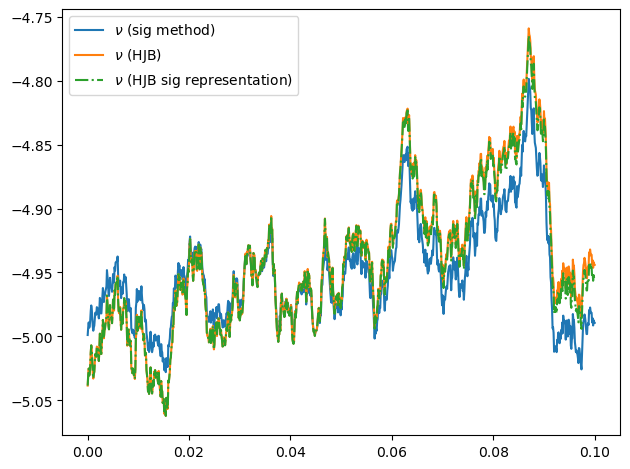

In [17]:
nsim = 0

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$ (sig method)')
plt.plot(env.timesteps, env_hjb.nu[:,nsim], label=r'$\nu$ (HJB)')
plt.plot(env.timesteps, env_hjb_sig.nu[:,nsim], label=r'$\nu$ (HJB sig representation)', linestyle='-.')
#plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

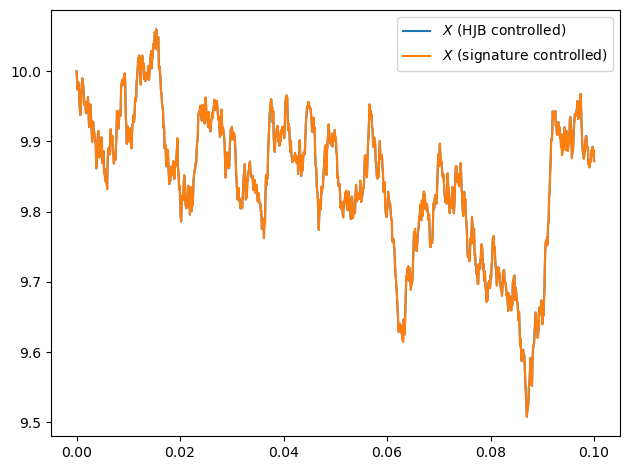

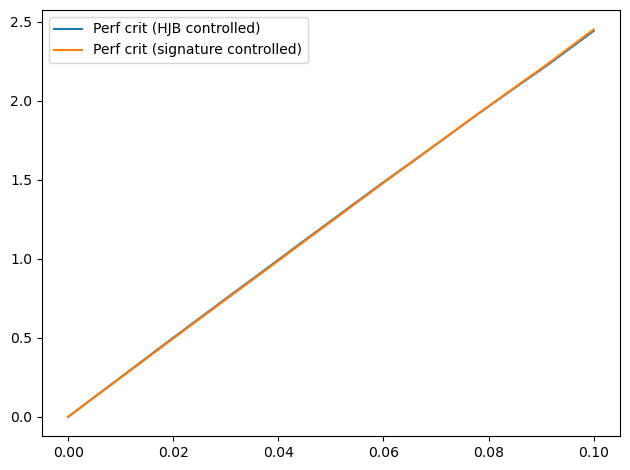

In [18]:
plt.plot(env.timesteps, env_hjb.X[:,nsim], label=r'$X$ (HJB controlled)')
plt.plot(env.timesteps, env.X[:, nsim], label=r'$X$ (signature controlled)')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env_hjb.run_crit[:,nsim], label=r'Perf crit (HJB controlled)')
plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit (signature controlled)')
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
print(f'Performance criterion\nSig: {env.performance.mean()}')

Performance criterion
Sig: 104.78954621760204


In [20]:
optimiser_1.value_fn(F, max_order_x = max_order_x, truncate_fn = True, max_order_fn = max_order_fn)

tensor([101.8690], grad_fn=<AddBackward0>)

In [21]:
# # f_s_sig = problem1.sig_strag_dot_1(f_s, order = trunc_lev)
# # f_alpha_sig = problem1.sig_strag_dot_1(f_alpha, order = trunc_lev_1)
# # f_perf_crit = problem1.sig_strag_dot_1(p_perf, order = order)

# max_order = max(max_order_x, max_order_fn)

# nsim = 1

# LF = optimiser_1.LF(optimiser_1.F, max_order = max_order_x)
# p_perf = optimiser_1.p_perf
# p_perf_run = optimiser_1.p_perf_run

# f_x_sig = lqproblem.sig_strag_dot_2(LF, order = max_order_x)
# f_perf_crit_run = lqproblem.sig_strag_dot_2(p_perf_run, order = max_order_fn)

# X_sig = np.zeros((env.Nt+1,))
# perf_hist = np.zeros((env.Nt+1,))

# W_sig = np.zeros(((env.dim**(max_order+1) - env.dim)//(env.dim - 1),))

# X_sig[0] = f_x_sig(env,W_sig,dim,0)
# perf_hist[0] = f_perf_crit_run(env,W_sig,dim,0)

# # S_sig = f_s_sig(env)
# # alpha_hat_sig = f_alpha_sig(env)
# # perf_hist = f_perf_crit(env)

# for it in range(1,env.Nt+1):
#     path_increment = np.array([env.timesteps[it]-env.timesteps[it-1], env.W[it,nsim]-env.W[it-1,nsim]])
#     W_sig[:] = iisignature.sigjoin(W_sig[:], path_increment, max_order)
#     X_sig[it] = f_x_sig(env,W_sig,dim,it)
#     perf_hist[it] = f_perf_crit_run(env,W_sig,dim,it)
#     #S_sig[it,:] = strag_sig(env,it)

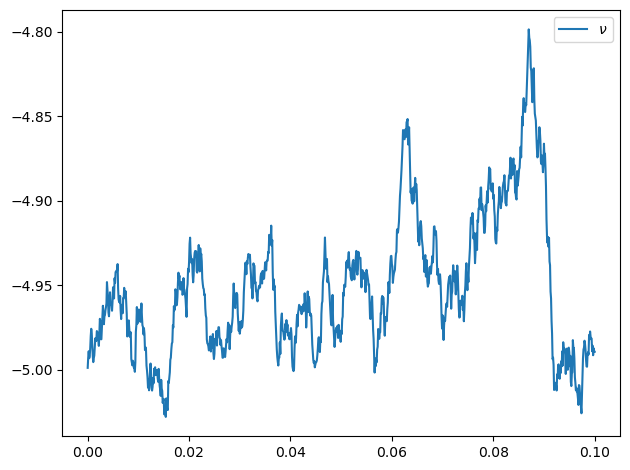

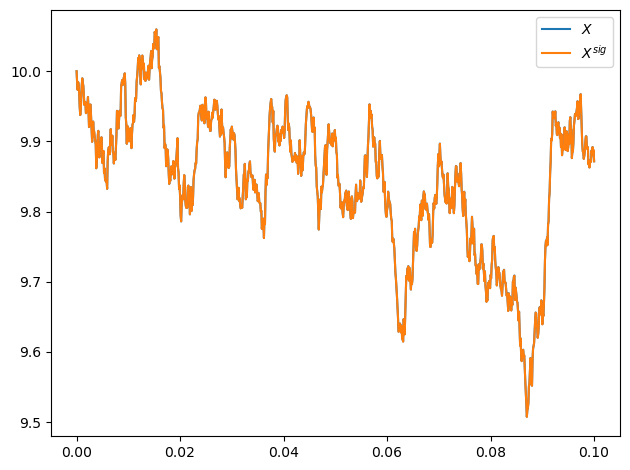

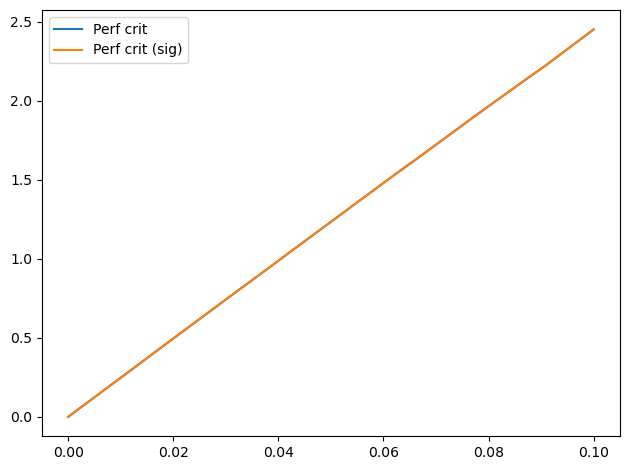

In [22]:
nsim = 0

max_order = max(max_order_x, max_order_fn)

LF = optimiser_1.LF(optimiser_1.F, max_order = max_order_x)
p_perf = optimiser_1.p_perf
p_perf_run = optimiser_1.p_perf_run

f_x_sig = lqproblem.sig_strag_dot_2(LF, order = max_order_x)
f_perf_crit_run = lqproblem.sig_strag_dot_2(p_perf_run, order = max_order_fn)

X_sig = np.zeros((env.Nt+1,))
perf_hist = np.zeros((env.Nt+1,))

W_sig = np.zeros(((env.dim**(max_order+1) - env.dim)//(env.dim - 1),))

X_sig[0] = f_x_sig(env,W_sig,dim,0)
perf_hist[0] = f_perf_crit_run(env,W_sig,dim,0)

# S_sig = f_s_sig(env)
# alpha_hat_sig = f_alpha_sig(env)
# perf_hist = f_perf_crit(env)

for it in range(1,env.Nt+1):
    path_increment = np.array([env.timesteps[it]-env.timesteps[it-1], env.W[it,nsim]-env.W[it-1,nsim]])
    W_sig[:] = iisignature.sigjoin(W_sig[:], path_increment, max_order)
    X_sig[it] = f_x_sig(env,W_sig,dim,it)
    perf_hist[it] = f_perf_crit_run(env,W_sig,dim,it)
    #S_sig[it,:] = strag_sig(env,it)

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.X[:,nsim], label=r'$X$')
plt.plot(env.timesteps, X_sig[:], label=r'$X^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit')
plt.plot(env.timesteps[:], perf_hist[:], label=r'Perf crit (sig)')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# with open('F_optimised_problem2.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()

In [21]:
LF.order

8